# Etapa II · Fase 3: selección, errores y test

**Estado:** la Fase 3 ya se ejecutó con la selección congelada en dev. Este notebook
documenta esos resultados; **no vuelve a evaluar test**.

| | |
|---|---|
| **Selección** | Mejor macro-F1 en dev por modelo; empate (<1 punto) por CV y simplicidad |
| **Ganador global** | C02: LogisticRegression, N2, TF-IDF (1,1) |
| **Test** | Una sola evaluación, después de reajustar en train+dev |
| **Errores** | 10 documentos de dev revisados |

In [1]:
%matplotlib inline

In [2]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mplconfig")
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)
print("Raíz:", ROOT)


Raíz: /home/mrangello/Documentos/PracticaML


In [3]:
exp = pd.read_csv(ROOT / "results/etapa2/experiments.tsv", sep="\t",
                   dtype=str, keep_default_na=False)

def dev_macro_f1(row):
    return float(row["dev_metric"].split("macro_f1=")[1].split(";")[0])

def extra_dict(row):
    return dict(part.split("=", 1) for part in row["extra"].split("; "))

def get(exp_id):
    return exp[exp["experiment_id"] == exp_id].iloc[0]


## 1. Selección por clasificador

In [4]:
selection = exp[exp["experiment_id"].isin(["C07", "C02", "C06"])][[
    "experiment_id", "method", "normalization", "representation",
    "ngram_range", "svd_components", "hyperparameters", "cv_macro_f1", "dev_metric"
]]
display(selection)

,experiment_id,method,normalization,representation,ngram_range,svd_components,hyperparameters,cv_macro_f1,dev_metric
1,C02,LogisticRegression,N2,tfidf,"(1,1)",,C=1; min_df=1,0.7675,macro_f1=0.7993; accuracy=0.8000
5,C06,SVC,N0,tfidf,"(1,1)",,C=10; min_df=1,0.7451,macro_f1=0.7742; accuracy=0.7733
6,C07,MultinomialNB,N1,tfidf,"(1,1)",,alpha=0.1; min_df=2,0.7612,macro_f1=0.7745; accuracy=0.7733


**Lectura:** C07 (NB+N1) 0.7745, C02 (LR+N2) 0.7993 y C06 (SVC+N0) 0.7742. El ganador
global es C02. C18 (LR+bigramas) da 0.8007, pero la diferencia con C02 es 0.0014 (<1 punto)
y su CV es menor; se mantiene C02.

## 2. Evaluación final en test

In [5]:
metrics = pd.read_csv(ROOT / "results/etapa2/classification_metrics.tsv", sep="\t")
display(metrics.round(4))

,experiment_id,model,split,accuracy,macro_precision,macro_recall,macro_f1
0,C07,MultinomialNB,dev,0.7733,0.7854,0.7749,0.7745
1,C02,LogisticRegression,dev,0.8000,0.8009,0.8019,0.7993
2,C06,SVC,dev,0.7733,0.7830,0.7741,0.7742
3,test,LogisticRegression,test,0.7600,0.7675,0.7617,0.7610


In [6]:
per_class = pd.read_csv(ROOT / "results/etapa2/classification_per_class.tsv", sep="\t")
display(per_class[per_class["split"] == "test"].round(4))

,experiment_id,model,split,label,precision,recall,f1,support
12,test,LogisticRegression,test,cs.CL,0.5789,0.5789,0.5789,19
13,test,LogisticRegression,test,cs.CV,0.8750,0.7368,0.8000,19
14,test,LogisticRegression,test,cs.IR,0.8889,0.8421,0.8649,19
15,test,LogisticRegression,test,cs.LG,0.7273,0.8889,0.8000,18


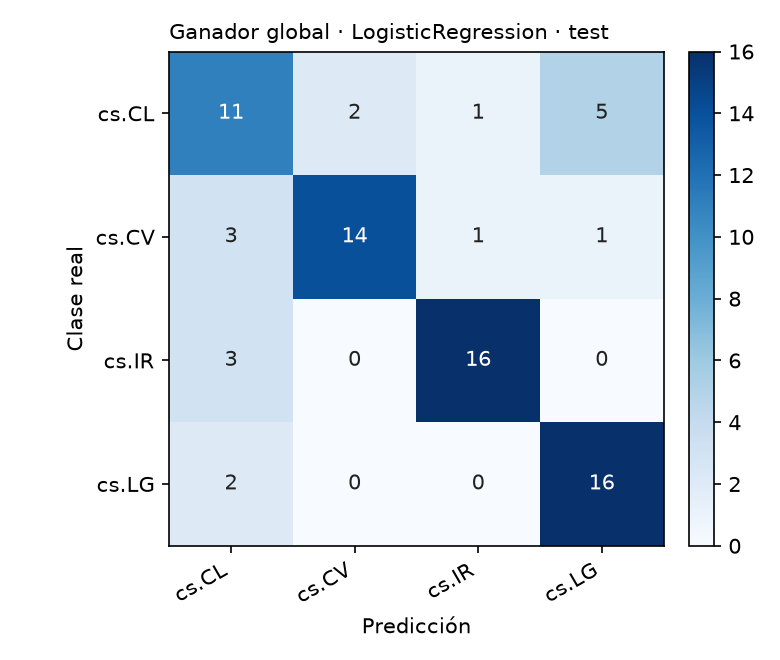

In [7]:
display(Image(filename=str(ROOT / "results/etapa2/confusion_matrices/test.png")))

**Lectura:** accuracy 0.760 y macro-F1 0.761. La clase más difícil es `cs.CL`
(F1 0.579); `cs.IR` y `cs.CV` llegan a 0.865 y 0.800. El descenso respecto a dev (0.799) es
de 3.8 puntos, esperable con 75 documentos.

## 3. Los 10 errores de dev

In [8]:
from src.etapa2.final import pick_diverse, explain_error

raw = pd.read_csv(ROOT / "data/scientific_raw_corpus.tsv", sep="\t",
                  dtype=str, keep_default_na=False)
dev = pd.read_csv(ROOT / "results/etapa2/runs/C02/dev_predictions.tsv", sep="\t",
                  dtype=str, keep_default_na=False)
errors = dev[dev["gold_label"] != dev["predicted_label"]].merge(
    raw[["arxiv_id", "title", "abstract", "categories"]],
    left_on="document_id", right_on="arxiv_id", how="left")
errors["cause"] = errors.apply(explain_error, axis=1)

picked = pick_diverse(errors, 10)
error_table = pd.DataFrame([{
    "document_id": r["document_id"], "Gold": r["gold_label"],
    "Predicho": r["predicted_label"], "Título": str(r["title"])[:75],
    "Categorías": r["categories"], "Causa": r["cause"],
} for r in picked])
display(error_table)

,document_id,Gold,Predicho,Título,Categorías,Causa
0,2609.39460,cs.CL,cs.CV,Right-Wing Rock or Just Rock? A Computational Linguistic Analysis of Frei.W,cs.CL,"error de generalización: el abstract es de lingüística computacional, pero acumula voc..."
1,2610.06902,cs.CL,cs.IR,Tree Navigation Without LLM Summaries: A Matched-Cost Study of Hierarchical,cs.CL cs.IR,cross-listing: el artículo también está listado en cs.IR
2,2609.39982,cs.CL,cs.LG,Mid-Harness: Scaling Actions Between Model and Harness for Terminal Agents,cs.CL cs.AI cs.MA,"frontera difusa LLM/ML: comparten transformer, training, model, language"
3,2610.00825,cs.CV,cs.CL,Align Then Reason: A Multimodal Lip-Sync Judge for Dubbing,cs.CV,visión-lenguaje/multimodal: menciona modelos de lenguaje e imágenes
4,2609.40222,cs.CV,cs.LG,LOCI: Spatial Linear Memory for Streaming World Models,cs.CV,"world models de vídeo: mezcla atención, memoria y transformers (LG) con escenas, cámar..."
5,2609.28383,cs.IR,cs.LG,Beyond a Scalar: Distributional Serving Interfaces for Watch-Time Predictio,cs.IR,recommendation/ranking con métodos de ML
6,2610.00767,cs.LG,cs.CL,"Pre-training interventions, ex post facto: Grafting model beliefs across ch",cs.LG cs.AI cs.CL,cross-listing: el artículo también está listado en cs.CL
7,2610.02251,cs.LG,cs.CV,Rank-Aware Speculative Sampling for Diffusion Draft Trees,cs.LG stat.CO,"el artículo es de muestreo especulativo (ML), pero evalúa generación en pixel-space, F..."
8,2610.02249,cs.LG,cs.IR,Nearest-neighbour baselines for fingerprint prediction from MS/MS spectra u,cs.LG cs.CE stat.ML,usa retrieval de vecinos cercanos como método; el vocabulario de búsqueda y benchmarki...
9,2609.38861,cs.CL,cs.IR,"TRACE: Target-Aware Retrieval, Attributed Evidence, and Contract-Constraine",cs.CL cs.DL cs.IR,cross-listing: el artículo también está listado en cs.IR


In [9]:
display(errors.groupby(["gold_label", "predicted_label"]).size()
        .rename("documentos").reset_index())

,gold_label,predicted_label,documentos
0,cs.CL,cs.CV,1
1,cs.CL,cs.IR,3
2,cs.CL,cs.LG,2
3,cs.CV,cs.CL,3
4,cs.CV,cs.LG,1
5,cs.IR,cs.LG,1
6,cs.LG,cs.CL,2
7,cs.LG,cs.CV,1
8,cs.LG,cs.IR,1


**Lectura:** 15 errores de 75 (20 %); solo 3 tienen la clase predicha dentro del
cross-listing. La mayoría se explica por solapamiento de vocabulario en las fronteras
`cs.CL`--`cs.LG`, `cs.CL`--`cs.IR` y `cs.CV`--`cs.CL`. El detalle completo está en
`results/etapa2/error_analysis.md`.

## 4. Cierre de la tarea B

In [10]:
summary = pd.read_csv(ROOT / "results/etapa2/cluster_summary.tsv", sep="\t")
display(summary[["cluster_id", "size", "top_words"]])

,cluster_id,size,top_words
0,0,192,"training, task, language, token, datum, improve, prompt, target, base, reasoning"
1,1,156,"retrieval, evidence, item, recommendation, query, user, base, agent, language, search"
2,2,113,"video, image, visual, generation, scene, training, physical, benchmark, introduce, rep..."
3,3,39,"parameter, training, learn, attention, cost, scale, noise, long, introduce, feature"


K-Means quedó seleccionado en **K02** (k=4, N2, TF-IDF, SVD 100): silhouette test
0.083, ARI 0.372, NMI 0.486. El detalle está en el notebook 13 y en
`results/etapa2/cluster_analysis.md`.

## 5. Conclusiones de la Fase 3

- **C02** es el modelo final: LR + N2 + TF-IDF (1,1), test macro-F1 0.761.
- **`cs.CL`** es la clase más difícil en dev y test; la frontera con `cs.LG` es el foco
  principal de error.
- La selección se congeló antes de test y no se cambió con el complemento C-5 (C29).
- Test se evaluó una sola vez.